In [4]:
import numpy as np, pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (make_scorer, matthews_corrcoef, classification_report,
                             ConfusionMatrixDisplay, accuracy_score, f1_score)
import matplotlib.pyplot as plt

df = pd.read_csv('yeast.csv')
X = df.drop(columns="name").to_numpy()
y = df["name"].to_numpy()
print(y.size, 'rows |', len(np.unique(y)), 'classes')
print(pd.Series(y).value_counts())

1484 rows | 10 classes
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scoring = {'accuracy': 'accuracy', 'f1': 'f1_macro', 'recall': 'recall_macro',
           'mcc': make_scorer(matthews_corrcoef), 'auc': 'roc_auc_ovr'}

def evaluate(model):
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring)
    return pd.Series({m: scores[f'test_{m}'].mean() for m in scoring}).round(3)

baseline = evaluate(DecisionTreeClassifier(random_state=0))
baseline

accuracy    0.514
f1          0.407
recall      0.407
mcc         0.375
auc         0.672
dtype: float64

In [6]:
params = {'max_depth': [3, 5, 8, None], 'min_samples_leaf': [1, 5, 10],
          'criterion': ['gini', 'entropy']}
tuned_model = GridSearchCV(DecisionTreeClassifier(random_state=0), params,
                           scoring='f1_macro', cv=4)
tuned = evaluate(tuned_model)
pd.DataFrame({'baseline': baseline, 'tuned': tuned})

,baseline,tuned
accuracy,0.514,0.562
f1,0.407,0.423
recall,0.407,0.433
mcc,0.375,0.431
auc,0.672,0.782


              precision    recall  f1-score   support

         CYT       0.51      0.62      0.56       463
         ERL       0.33      0.20      0.25         5
         EXC       0.53      0.46      0.49        35
         ME1       0.63      0.70      0.67        44
         ME2       0.47      0.35      0.40        51
         ME3       0.71      0.86      0.78       163
         MIT       0.59      0.45      0.51       244
         NUC       0.56      0.53      0.54       429
         POX       0.75      0.15      0.25        20
         VAC       0.00      0.00      0.00        30

    accuracy                           0.56      1484
   macro avg       0.51      0.43      0.45      1484
weighted avg       0.56      0.56      0.55      1484



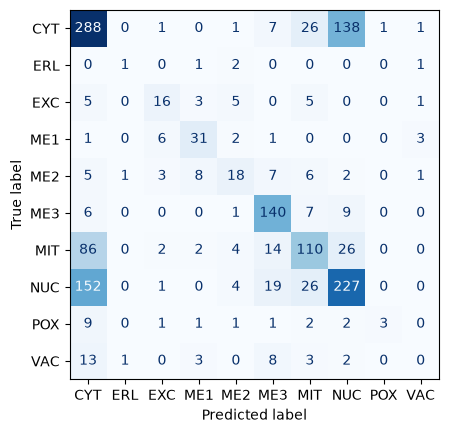

In [7]:
pred = cross_val_predict(tuned_model, X, y, cv=cv)
print(classification_report(y, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y, pred, cmap='Blues', colorbar=False)
plt.show()

In [9]:
def gini(y):
    p = np.unique(y, return_counts=True)[1] / len(y)
    return 1 - (p ** 2).sum()

class MyTree:
    def __init__(self, max_depth=5, min_leaf=5):
        self.max_depth, self.min_leaf = max_depth, min_leaf

    def fit(self, X, y, depth=0):
        self.label = pd.Series(y).mode()[0]
        best_gain, self.feature, self.threshold = 0, None, None
        if depth < self.max_depth and gini(y) > 0:
            for j in range(X.shape[1]):
                values = np.unique(X[:, j])
                for t in (values[:-1] + values[1:]) / 2:
                    left = X[:, j] <= t
                    if left.sum() < self.min_leaf or (~left).sum() < self.min_leaf:
                        continue
                    gain = gini(y) - left.mean()*gini(y[left]) - (~left).mean()*gini(y[~left])
                    if gain > best_gain:
                        best_gain, self.feature, self.threshold = gain, j, t
        self.left = self.right = None
        if self.feature is not None:
            left = X[:, self.feature] <= self.threshold
            self.left = MyTree(self.max_depth, self.min_leaf).fit(X[left], y[left], depth+1)
            self.right = MyTree(self.max_depth, self.min_leaf).fit(X[~left], y[~left], depth+1)
        return self

    def predict_one(self, x):
        if self.left is None:
            return self.label
        branch = self.left if x[self.feature] <= self.threshold else self.right
        return branch.predict_one(x)

    def predict(self, X):
        return np.array([self.predict_one(x) for x in X])

In [10]:
models = {'scratch': MyTree(5, 5),
          'sklearn': DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=0)}
results = {name: [] for name in models}

for train, test in cv.split(X, y):
    for name, model in models.items():
        pred = model.fit(X[train], y[train]).predict(X[test])
        results[name].append([accuracy_score(y[test], pred),
                              f1_score(y[test], pred, average='macro'),
                              matthews_corrcoef(y[test], pred)])

pd.DataFrame({name: np.mean(scores, axis=0) for name, scores in results.items()},
             index=['accuracy', 'macro F1', 'MCC']).round(3)

,scratch,sklearn
accuracy,0.573,0.572
macro F1,0.425,0.422
MCC,0.447,0.445
